# Exploratory Data Analysis about PowerCo 

This analysis we're engaged in the understanding of PowerCo business model. 

In [218]:
# Import the packages
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 

print('All set')

All set


## Loan datas: 

client_data: it is a historical data about customer such as usage,sign up date, forecasted usage etc. 
Historical pricing data: it is a record of variable and fixed data at different point in time. 


In [306]:
# Loaning

client= pd.read_csv(r'/Users/Rushaner/Desktop/Job simulation and Project /Job Simulation/BCG X (PowerCo)/client_data (1).csv')
price= pd.read_csv(r'/Users/Rushaner/Desktop/Job simulation and Project /Job Simulation/BCG X (PowerCo)/price_data (1).csv')

print("Succefully loaned")

Succefully loaned


In [ ]:
client

# Struture and information of the data

In [305]:

def infom(df):
    
    # Client_data estruct 
    print(f"Clients data is structure by {df.shape[0]} rows, and {df.shape[1]} columns")
    print("\n")
    # Searching for missing value 
    print(f"The empty values in cliente data frame are = {df.isna().sum().sum()}")
    print("\n")
    
    # Duplicate clients 
    print(f'Duplicate clients are: {df['id'].duplicated().sum()}')
    
    print("\n")
    return display(df.info())

# Printing the informacion about the data 
infom(client)
infom(price)


Clients data is structure by 14606 rows, and 26 columns


The empty values in cliente data frame are = 0


Duplicate clients are: 0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14606 entries, 0 to 14605
Data columns (total 26 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              14606 non-null  object 
 1   channel_sales                   14606 non-null  object 
 2   cons_12m                        14606 non-null  int64  
 3   cons_gas_12m                    14606 non-null  int64  
 4   cons_last_month                 14606 non-null  int64  
 5   date_activ                      14606 non-null  object 
 6   date_end                        14606 non-null  object 
 7   date_modif_prod                 14606 non-null  object 
 8   date_renewal                    14606 non-null  object 
 9   forecast_cons_12m               14606 non-null  float64
 10  forecast_cons_year  

None

Clients data is structure by 193002 rows, and 8 columns


The empty values in cliente data frame are = 0


Duplicate clients are: 176906


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 193002 entries, 0 to 193001
Data columns (total 8 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   id                  193002 non-null  object 
 1   price_date          193002 non-null  object 
 2   price_off_peak_var  193002 non-null  float64
 3   price_peak_var      193002 non-null  float64
 4   price_mid_peak_var  193002 non-null  float64
 5   price_off_peak_fix  193002 non-null  float64
 6   price_peak_fix      193002 non-null  float64
 7   price_mid_peak_fix  193002 non-null  float64
dtypes: float64(6), object(2)
memory usage: 11.8+ MB


None

# Date Transformations

In [310]:
# Date transfomation 

date_client=  ['date_activ', 'date_end', 'date_modif_prod', 'date_renewal']

for col in date_client:
    client[col] = pd.to_datetime(
        client[col], 
        errors= 'coerce'
    )

client['has_gas_1']= np.where(client['has_gas'] == "t", 1, 0)


price['price_date'] = pd.to_datetime(
    price['price_date'],
    errors= 'coerce'
)   

---
## Descriptive Statistic Analysis 

### Displaying the Data metrics 

In [ ]:
# Viewing the data 
display(client.head())

# Summarizing the data using descriptive statistics 
# cliente 
print("Clients DataFrame")
display(client.describe())



,id,channel_sales,cons_12m,cons_gas_12m,cons_last_month,date_activ,date_end,date_modif_prod,date_renewal,forecast_cons_12m,...,has_gas,imp_cons,margin_gross_pow_ele,margin_net_pow_ele,nb_prod_act,net_margin,num_years_antig,origin_up,pow_max,churn
0,24011ae4ebbe3035111d65fa7c15bc57,foosdfpfkusacimwkcsosbicdxkicaua,0,54946,0,2013-06-15,2016-06-15,2015-11-01,2015-06-23,0.00,...,t,0.00,25.44,25.44,2,678.99,3,lxidpiddsbxsbosboudacockeimpuepw,43.648,1
1,d29c2c54acc38ff3c0614d0a653813dd,MISSING,4660,0,0,2009-08-21,2016-08-30,2009-08-21,2015-08-31,189.95,...,f,0.00,16.38,16.38,1,18.89,6,kamkkxfxxuwbdslkwifmmcsiusiuosws,13.800,0
2,764c75f661154dac3a6c254cd082ea7d,foosdfpfkusacimwkcsosbicdxkicaua,544,0,0,2010-04-16,2016-04-16,2010-04-16,2015-04-17,47.96,...,f,0.00,28.60,28.60,1,6.60,6,kamkkxfxxuwbdslkwifmmcsiusiuosws,13.856,0
3,bba03439a292a1e166f80264c16191cb,lmkebamcaaclubfxadlmueccxoimlema,1584,0,0,2010-03-30,2016-03-30,2010-03-30,2015-03-31,240.04,...,f,0.00,30.22,30.22,1,25.46,6,kamkkxfxxuwbdslkwifmmcsiusiuosws,13.200,0
4,149d57cf92fc41cf94415803a877cb4b,MISSING,4425,0,526,2010-01-13,2016-03-07,2010-01-13,2015-03-09,445.75,...,f,52.32,44.91,44.91,1,47.98,6,kamkkxfxxuwbdslkwifmmcsiusiuosws,19.800,0


Clients DataFrame


,cons_12m,cons_gas_12m,cons_last_month,date_activ,date_end,date_modif_prod,date_renewal,forecast_cons_12m,forecast_cons_year,forecast_discount_energy,...,forecast_price_energy_peak,forecast_price_pow_off_peak,imp_cons,margin_gross_pow_ele,margin_net_pow_ele,nb_prod_act,net_margin,num_years_antig,pow_max,churn
count,1.460600e+04,1.460600e+04,14606.000000,14606,14606,14606,14606,14606.000000,14606.000000,14606.000000,...,14606.000000,14606.000000,14606.000000,14606.000000,14606.000000,14606.000000,14606.000000,14606.000000,14606.000000,14606.000000
mean,1.592203e+05,2.809238e+04,16090.269752,2011-01-28 07:54:18.879912448,2016-07-27 20:48:26.422018560,2013-01-02 12:29:10.951663872,2015-07-21 06:59:00.353279488,1868.614880,1399.762906,0.966726,...,0.050491,43.130056,152.786896,24.565121,24.562517,1.292346,189.264522,4.997809,18.135136,0.097152
min,0.000000e+00,0.000000e+00,0.000000,2003-05-09 00:00:00,2016-01-28 00:00:00,2003-05-09 00:00:00,2013-06-26 00:00:00,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,3.300000,0.000000
25%,5.674750e+03,0.000000e+00,0.000000,2010-01-15 00:00:00,2016-04-27 06:00:00,2010-08-12 00:00:00,2015-04-17 00:00:00,494.995000,0.000000,0.000000,...,0.000000,40.606701,0.000000,14.280000,14.280000,1.000000,50.712500,4.000000,12.500000,0.000000
50%,1.411550e+04,0.000000e+00,792.500000,2011-03-04 00:00:00,2016-08-01 00:00:00,2013-06-19 00:00:00,2015-07-27 00:00:00,1112.875000,314.000000,0.000000,...,0.084138,44.311378,37.395000,21.640000,21.640000,1.000000,112.530000,5.000000,13.856000,0.000000
75%,4.076375e+04,0.000000e+00,3383.000000,2012-04-19 00:00:00,2016-10-31 00:00:00,2015-06-16 00:00:00,2015-10-29 00:00:00,2401.790000,1745.750000,0.000000,...,0.098837,44.311378,193.980000,29.880000,29.880000,1.000000,243.097500,6.000000,19.172500,0.000000
max,6.207104e+06,4.154590e+06,771203.000000,2014-09-01 00:00:00,2017-06-13 00:00:00,2016-01-29 00:00:00,2016-01-28 00:00:00,82902.830000,175375.000000,30.000000,...,0.195975,59.266378,15042.790000,374.640000,374.640000,32.000000,24570.650000,13.000000,320.000000,1.000000
std,5.734653e+05,1.629731e+05,64364.196422,NaN,NaN,NaN,NaN,2387.571531,3247.786255,5.108289,...,0.049037,4.485988,341.369366,20.231172,20.230280,0.709774,311.798130,1.611749,13.534743,0.296175


Index(['id', 'channel_sales', 'cons_12m', 'cons_gas_12m', 'cons_last_month',
       'date_activ', 'date_end', 'date_modif_prod', 'date_renewal',
       'forecast_cons_12m', 'forecast_cons_year', 'forecast_discount_energy',
       'forecast_meter_rent_12m', 'forecast_price_energy_off_peak',
       'forecast_price_energy_peak', 'forecast_price_pow_off_peak', 'has_gas',
       'imp_cons', 'margin_gross_pow_ele', 'margin_net_pow_ele', 'nb_prod_act',
       'net_margin', 'num_years_antig', 'origin_up', 'pow_max', 'churn'],
      dtype='object')


In [338]:
def plot_stk_bar(df,title, size_= (18,20), rot_= 0, lenged_= "upper right"): 
    """_summary_
    Plot stacked bar with annotations
    
    Args:
        df (_type_): dataframe
        title (str, optional): title of the graph
        size (tuple, optional): _description_. Defaults to (18,20).
        ro_ (int, optional): _description_. Defaults to 0.
        lenged_ (str, optional): _description_. Defaults to "upper right".
    """
    
    ax= df.plot(
        kind= "bar", 
        stacked= True,
        figsize= size_,
        rot= rot_, 
        title= title
        
        
    )
    
    # Annotate bar 
    annotate_stacked_bars(ax, textsize= 14)
    # Rename legend
    plt.legend(["Retention", "Churn"], loc= lenged_)
    plt.ylabel("Company Base (%)")
    plt.show()
    
    
def annotate_stacked_bars(ax, pad= 0.99, colour= "white", textsize= 13):
        
    """_summary_

    Args:
        ax (chart): _description_
        pad (float, optional): _description_. Defaults to 0.99.
        colour (str, optional): _description_. Defaults to "white".
        textsize (int, optional): _description_. Defaults to 13.
    """
    
    # Iterate over the plotted rectanges/bars
    for p in ax.patches:
        
        # Calculate annotation
        value = str(round(p.get_height(),1))
        # If value is 0 do not annotate
        if value == '0.0':
            continue
        ax.annotate(
            value,
            ((p.get_x()+ p.get_width()/2)*pad-0.05, (p.get_y()+p.get_height()/2)*pad),
            color=colour,
            size=textsize
        )

#### Statistic 

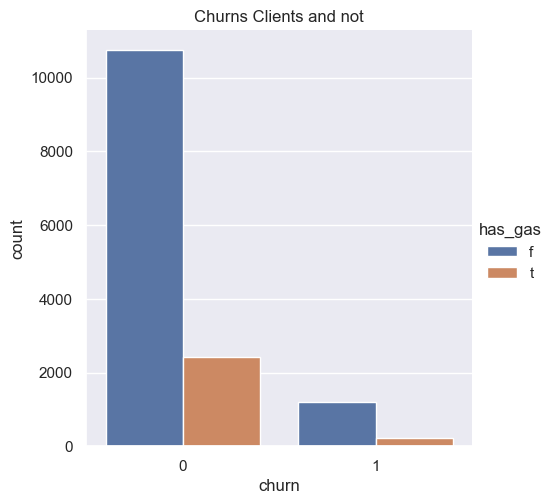

has_gas,f,t
churn,,
0,10753,2434
1,1202,217


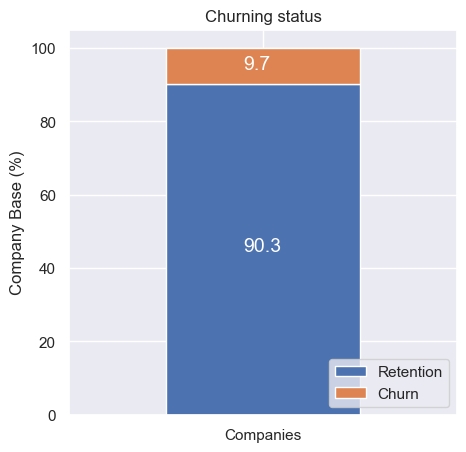

In [339]:
# Visualizing churn vs has_gas
ax1= sns.catplot(x= 'churn',
            data= client, 
            kind= 'count',
            hue= 'has_gas'
            )

ax1.set_titles("Churns Clients and not")
plt.title("Churns Clients and not")
plt.show()

# Cross tab of client 
display (pd.crosstab(client['churn'], client['has_gas']).style.background_gradient(cmap='summer_r'))


# Value counts of the churned clients 
churn= client[['id', 'churn']]
churn.columns= ['Companies', 'churn']
churn_tl= churn.groupby(['churn']).count()
churn_pgt= churn_tl/ churn_tl.sum() *100

plot_stk_bar(churn_pgt.transpose(), "Churning status", (5,5), lenged_= 'lower right')


In [331]:
churn_pgt.transpose()

churn,0,1
Companies,90.284814,9.715186


#### Finding (Observation)

* the 9.7% of the company clients has churned. 
* 92% of the churned clients had one service (energy) with the company


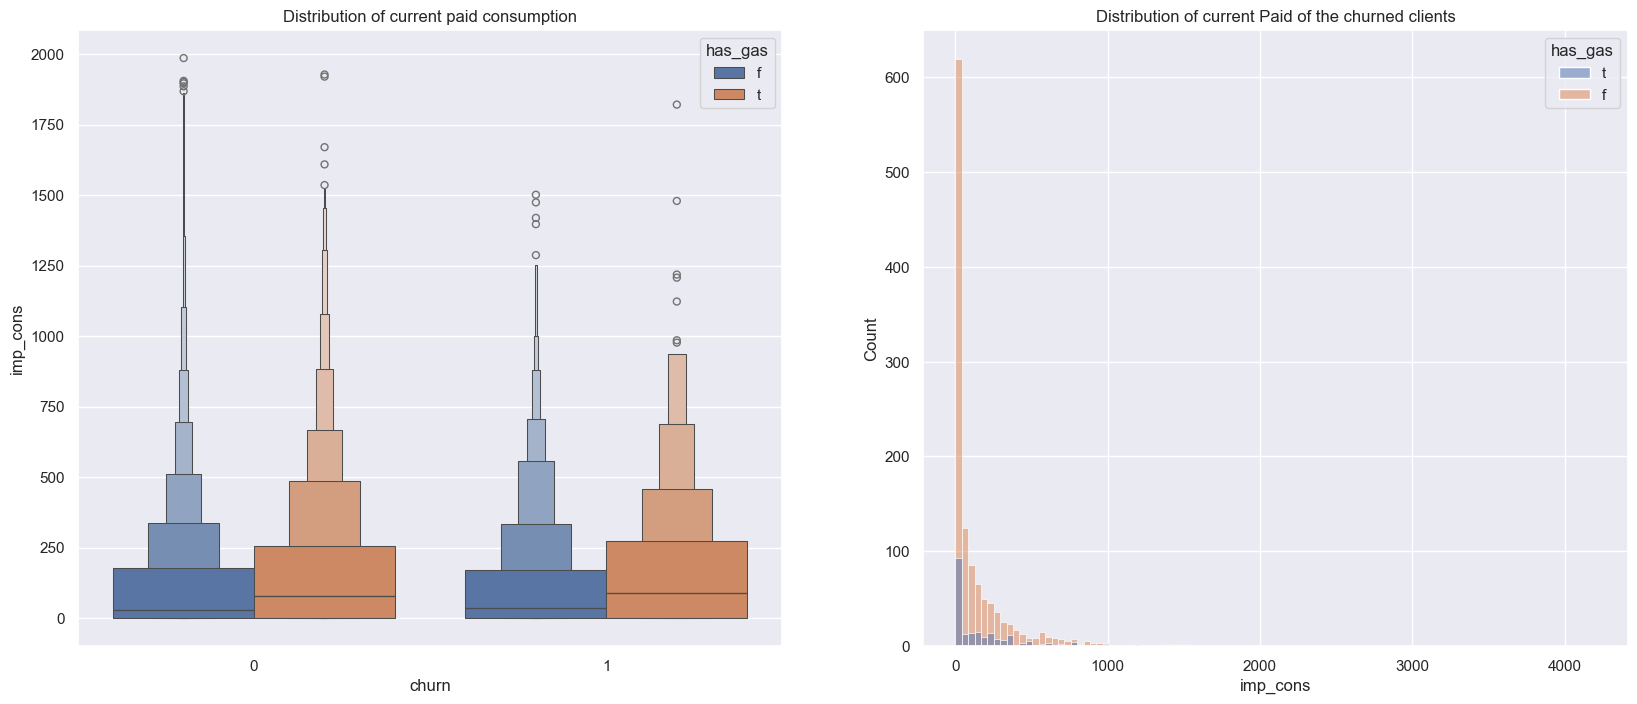

In [309]:
# Boxenplot imp_cons vs churn by has_has

fig, ax = plt.subplots(1,2, figsize= (20, 8))

ax[0].set_title('Distribution of current paid consumption')
sns.boxenplot(y= 'imp_cons', 
              x= 'churn',
              data= client[client['imp_cons']<=2000],
              hue= 'has_gas',
              ax= ax[0]
              )


   # Distribution of imp_cons of clients whose churned 
sns.histplot( x= 'imp_cons', 
            data= client[client['churn'] == 1],
            bins= 100,
            hue= 'has_gas',
            ax= ax[1]
            )           
ax[1].set_title("Distribution of current Paid of the churned clients")


plt.show()



## Finding (Observation)

* As a expected the median of those client rather that their status in the companya and also had gas is high than those who only contracted one service. 
* The distribution of those churned clients show the data less disperse than those who do not churn. **Are they more sensity to the price?**


<Axes: title={'center': 'Correlation Matrix'}>

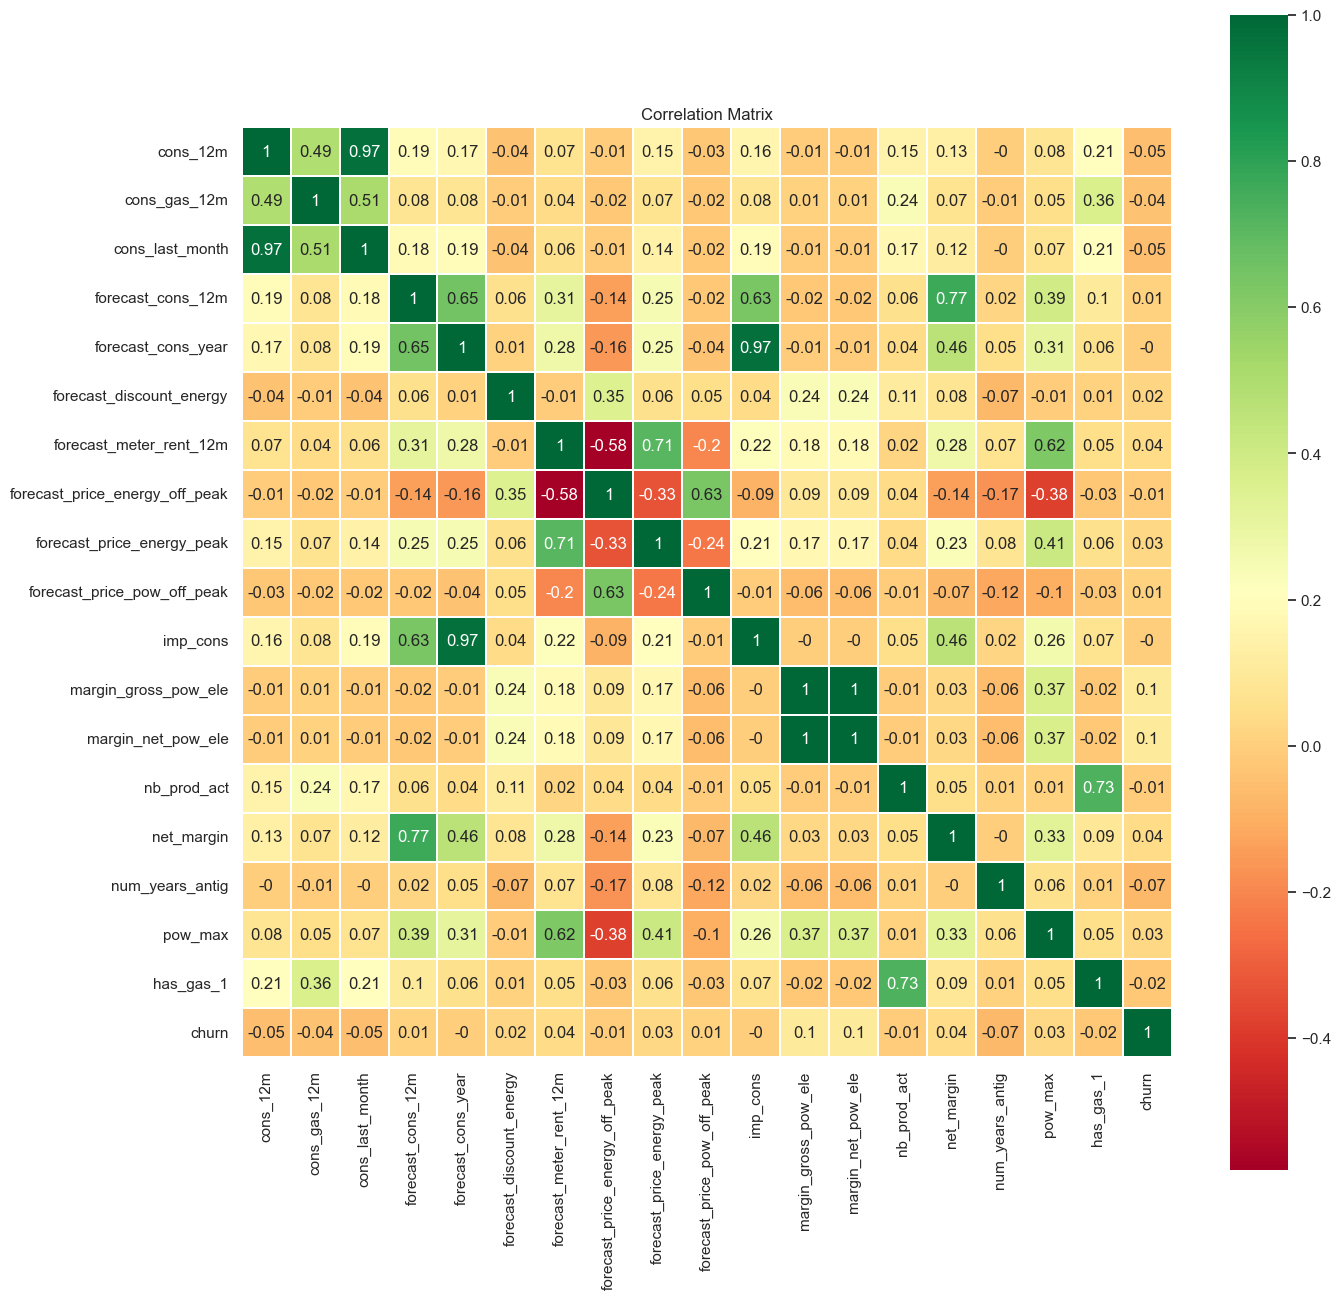

In [311]:
# Making a heap map of the target value 

variable= ["cons_12m",
           "cons_gas_12m",
           "cons_last_month",
        'forecast_cons_12m', 'forecast_cons_year', 'forecast_discount_energy',
       'forecast_meter_rent_12m', 'forecast_price_energy_off_peak',
       'forecast_price_energy_peak', 'forecast_price_pow_off_peak', 
       'imp_cons', 'margin_gross_pow_ele', 'margin_net_pow_ele', 'nb_prod_act',
       'net_margin', 'num_years_antig', 'pow_max', 'has_gas_1','churn']

client_corr= client[variable].corr().round(2)
plt.figure(figsize=(15,15))
plt.title("Correlation Matrix")
sns.heatmap(client_corr, vmax=1, square=True, annot= True, cmap= 'RdYlGn', yticklabels= True, linewidths=0.2)

### Finding 

* There are not strong correlation with the churn column, most of them are less than 0.1
* The number of active products and services has a negatie correlation. Does it become harder to change the supply company as more service a client demand?


In [273]:
# View data 
display(price.head())

# Summary statistic of price table

display(price.describe())

,id,price_date,price_off_peak_var,price_peak_var,price_mid_peak_var,price_off_peak_fix,price_peak_fix,price_mid_peak_fix
0,038af19179925da21a25619c5a24b745,2015-01-01,0.151367,0.0,0.0,44.266931,0.0,0.0
1,038af19179925da21a25619c5a24b745,2015-02-01,0.151367,0.0,0.0,44.266931,0.0,0.0
2,038af19179925da21a25619c5a24b745,2015-03-01,0.151367,0.0,0.0,44.266931,0.0,0.0
3,038af19179925da21a25619c5a24b745,2015-04-01,0.149626,0.0,0.0,44.266931,0.0,0.0
4,038af19179925da21a25619c5a24b745,2015-05-01,0.149626,0.0,0.0,44.266931,0.0,0.0


,price_date,price_off_peak_var,price_peak_var,price_mid_peak_var,price_off_peak_fix,price_peak_fix,price_mid_peak_fix
count,193002,193002.000000,193002.000000,193002.000000,193002.000000,193002.000000,193002.000000
mean,2015-06-16 12:50:49.933161216,0.141027,0.054630,0.030496,43.334477,10.622875,6.409984
min,2015-01-01 00:00:00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2015-04-01 00:00:00,0.125976,0.000000,0.000000,40.728885,0.000000,0.000000
50%,2015-07-01 00:00:00,0.146033,0.085483,0.000000,44.266930,0.000000,0.000000
75%,2015-10-01 00:00:00,0.151635,0.101673,0.072558,44.444710,24.339581,16.226389
max,2015-12-01 00:00:00,0.280700,0.229788,0.114102,59.444710,36.490692,17.458221
std,NaN,0.025032,0.049924,0.036298,5.410297,12.841895,7.773592


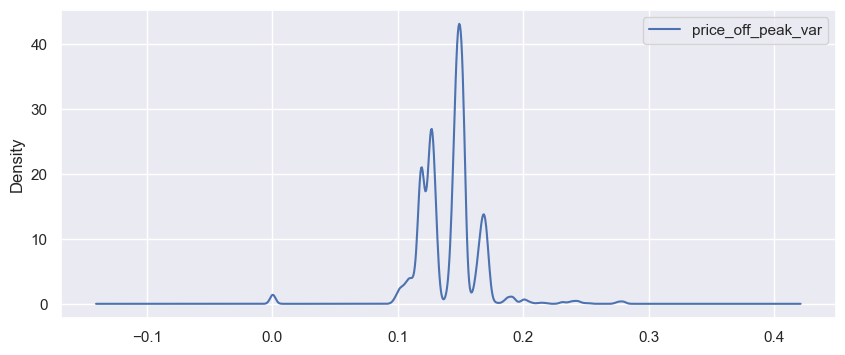

In [274]:
# Visualizing price  distribution in the 1st period
price['price_off_peak_var'].plot(kind= 'density',layout= (3,3), legend= True, figsize= (10, 4))
plt.show()

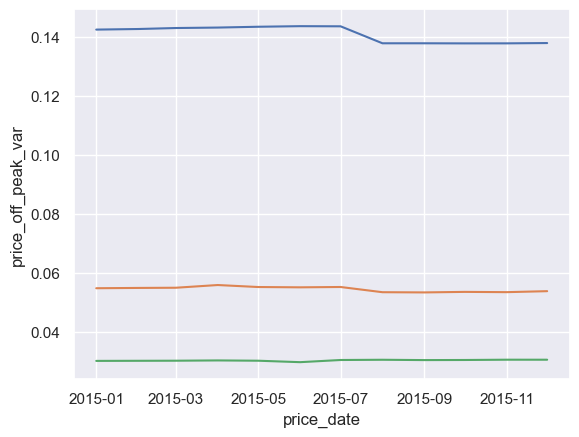

In [275]:
# Plot the average tren of price_off_peak_var 
sns.set_theme(style='darkgrid')
price_1st_v= price.groupby(['price_date'], as_index= False) ['price_off_peak_var'].mean()

price_2nd_v= price.groupby(['price_date'], as_index= False) ['price_peak_var'].mean()
price_3st_v= price.groupby(['price_date'], as_index= False) ['price_mid_peak_var'].mean()

f= sns.lineplot(
    x= 'price_date',
    y= 'price_off_peak_var',
    data= price_1st_v
    
)
f = sns.lineplot(
    x= 'price_date',
    y= 'price_peak_var',
    data= price_2nd_v
    
)

f= sns.lineplot(
    x= 'price_date',
    y= 'price_mid_peak_var',
    data= price_3st_v
)

plt.show()

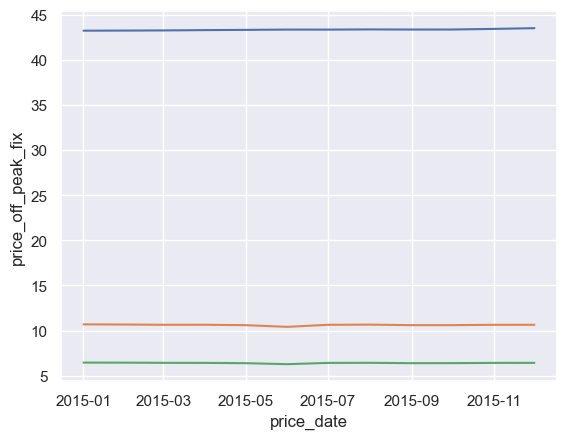

In [276]:
# Plot the average tren of price_off_peak_var 
sns.set_theme(style='darkgrid')
price_1st_f= price.groupby(['price_date'], as_index= False) ['price_off_peak_fix'].mean()
price_2nd_f= price.groupby(['price_date'], as_index= False) ['price_peak_fix'].mean()
price_3st_f= price.groupby(['price_date'], as_index= False) ['price_mid_peak_fix'].mean()

f= sns.lineplot(
    x= 'price_date',
    y= 'price_off_peak_fix',
    data= price_1st_f
    
)
f = sns.lineplot(
    x= 'price_date',
    y= 'price_peak_fix',
    data= price_2nd_f    
)

f= sns.lineplot(
    x= 'price_date',
    y= 'price_mid_peak_fix',
    data= price_3st_f
)

plt.show()

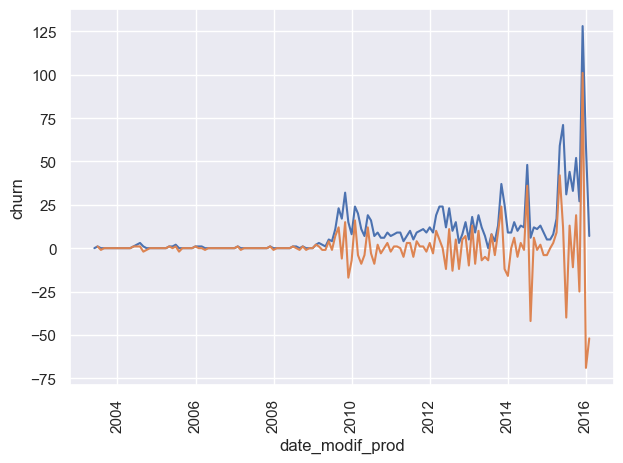

In [315]:
# Churned client trend 
churned_client= client.resample("ME", on= 'date_modif_prod',  ) ['churn'].sum().reset_index( )
churned_client['churn_d'] = churned_client['churn'].diff()
# Plot the end date of the churned clients 
chuc= sns.lineplot(
    x= 'date_modif_prod',
    y= 'churn', 
    data= churned_client
)

chuc= sns.lineplot(
    x= 'date_modif_prod',
    y= 'churn_d', 
    data= churned_client
)

chuc.tick_params(axis= 'x',
                 labelrotation= 90)
plt.tight_layout()

plt.show()

## Finding (Observation)

* Between 2014 and 2016 clients churning incresed rapidly. 
* At the end of 2015 reach the Peak of churning clients.
* Is the price the reason of why client churned? 